# Radial profiles for the Photutils H II candidates

This notebook reads the catalogue and refined labels produced by
`NGC253_HII_SNR_photutils_clean.ipynb`. It keeps both BPT-supported and
BPT-unavailable H II candidates. Inspection flags are displayed but do not
reject regions.


In [8]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from matplotlib.patches import Circle

pd.set_option("display.max_columns", 100)


In [9]:
checkpoint_dir = Path("./results_photutils")

catalog = pd.read_pickle(checkpoint_dir / "first_pass_catalog.pkl")
labels = fits.getdata(checkpoint_dir / "labels_data.fits").astype(np.int32)

with open(checkpoint_dir / "metadata.json") as file:
    metadata = json.load(file)

pix_scale = float(metadata.get("pix_scale_arcsec", 0.2))
data_fits = Path(metadata["input_fits_path"])

if not data_fits.exists():
    raise FileNotFoundError(
        f"The original MUSE FITS file was not found at:\n{data_fits}\n"
        "Change data_fits in this cell if the file has moved."
    )

# The Photutils notebook saves the catalogue and segmentation maps, but not
# duplicate copies of the original line maps. Load those maps from the same
# MUSE FITS file used to build the catalogue.
with fits.open(data_fits, memmap=True) as hdul:
    line_maps = {
        "ha": np.array(hdul["HA6562_FLUX"].data, dtype=float),
        "oiii": np.array(hdul["OIII5006_FLUX"].data, dtype=float),
        "sii": (
            np.array(hdul["SII6716_FLUX"].data, dtype=float)
            + np.array(hdul["SII6730_FLUX"].data, dtype=float)
        ),
    }

print("Catalog:", catalog.shape)
print("Image shape:", labels.shape)
print("Pixel scale:", pix_scale, "arcsec/pixel")
print("Input FITS:", data_fits)


Catalog: (1374, 137)
Image shape: (1733, 6080)
Pixel scale: 0.2 arcsec/pixel
Input FITS: /Users/golta/Desktop/Uni/Thesis/ADP.2025-07-06T07_52_11.876.fits


In [10]:
HII_TAGS = [
    "hii_candidate_bpt",
    "hii_candidate_no_bpt",
]

# The new Photutils catalogue does not reject masks. Background and edge
# problems are stored only as inspection flags, so they are not used here as
# selection cuts.
potential_hii = catalog[
    catalog["first_pass_tag"].isin(HII_TAGS)
].copy()

N_REGIONS = 3

REGION_IDS = (
    potential_hii
    .sort_values("npix", ascending=False)
    .head(N_REGIONS)["region_id"]
    .astype(int)
    .tolist()
)

# Manual alternative:
# REGION_IDS = [198, 205, 310]

selected_regions = (
    potential_hii[potential_hii["region_id"].isin(REGION_IDS)]
    .sort_values("npix", ascending=False)
)

print("Selected region IDs:", REGION_IDS)
display(
    selected_regions[
        [
            "region_id",
            "first_pass_tag",
            "npix",
            "r_eq_arcsec",
            "ha_contrast",
            "ha_bg_level",
            "sii_bg_level",
            "oiii_bg_level",
            "flag_needs_inspection",
        ]
    ]
)


Selected region IDs: [992, 195, 1126]


,region_id,first_pass_tag,npix,r_eq_arcsec,ha_contrast,ha_bg_level,sii_bg_level,oiii_bg_level,flag_needs_inspection
991,992,hii_candidate_bpt,2751,5.918346,17.513589,839.034149,372.189392,120.230247,False
194,195,hii_candidate_bpt,2678,5.839294,10.377595,403.160980,248.509338,66.756569,False
1125,1126,hii_candidate_bpt,2498,5.639639,8.505504,344.032898,203.985840,66.499886,False


In [11]:
'''
def log_ratio(numerator, denominator):
    """Return log10(numerator / denominator), or NaN for invalid fluxes."""
    if numerator > 0 and denominator > 0:
        return np.log10(numerator / denominator)
    return np.nan
'''
def log_ratio(numerator, denominator):
    """Return log10(numerator / denominator), or NaN for invalid fluxes."""
    if numerator > 0 and denominator > 0:
        return numerator / denominator
    return np.nan

def cutout_slices(mask, pad):
    """Bounding box of a mask, enlarged by `pad` pixels."""
    y, x = np.where(mask)

    if len(y) == 0:
        raise ValueError("The selected region mask is empty.")

    return np.s_[
        max(0, y.min() - pad):min(mask.shape[0], y.max() + pad + 1),
        max(0, x.min() - pad):min(mask.shape[1], x.max() + pad + 1),
    ]


def analyze_region(
    region_id,
    pad=50,
    annulus_width_arcsec=0.5,
    rmax_factor=2.0,
):
    """
    Measure H-alpha and line-ratio radial profiles for one region.

    `raw` uses the original line maps. `dig_sub` subtracts, from every pixel,
    the local median background level already saved for that region by the
    Photutils catalogue notebook.
    """
    region_id = int(region_id)
    full_region = labels == region_id

    if not np.any(full_region):
        raise ValueError(f"Region {region_id} is not present in labels_data.")

    row = catalog.loc[catalog["region_id"] == region_id]
    if row.empty:
        raise ValueError(f"Region {region_id} is not present in the catalog.")

    row = row.iloc[0]
    background = {
        line: float(row[f"{line}_bg_level"])
        for line in line_maps
    }

    slc = cutout_slices(full_region, pad)
    labels_cutout = labels[slc]
    region_mask = labels_cutout == region_id
    other_regions = (labels_cutout != 0) & (labels_cutout != region_id)
    maps = {
        line: image[slc]
        for line, image in line_maps.items()
    }

    y_region, x_region = np.where(region_mask)
    yc, xc = y_region.mean(), x_region.mean()
    r_eq_pix = np.sqrt(region_mask.sum() / np.pi)

    yy, xx = np.indices(region_mask.shape)
    radius_pix = np.hypot(yy - yc, xx - xc)

    dr_pix = annulus_width_arcsec / pix_scale
    edges = np.arange(0, rmax_factor * r_eq_pix + dr_pix, dr_pix)
    usable = ~other_regions

    ratio_pairs = {
        "sii_oiii": ("sii", "oiii"),
        "sii_ha": ("sii", "ha"),
        "oiii_ha": ("oiii", "ha"),
    }

    rows = []

    for bin_number, (r0, r1) in enumerate(zip(edges[:-1], edges[1:])):
        annulus = usable & (radius_pix >= r0) & (radius_pix < r1)
        n_pixels = np.count_nonzero(annulus)

        if n_pixels == 0:
            continue

        profile_row = {
            "region_id": region_id,
            "first_pass_tag": row["first_pass_tag"],
            "bin": bin_number,
            "r_mid_pix": 0.5 * (r0 + r1),
            "r_mid_arcsec": 0.5 * (r0 + r1) * pix_scale,
            "r_over_req": 0.5 * (r0 + r1) / r_eq_pix,
            "inside_region_fraction": (
                np.count_nonzero(annulus & region_mask) / n_pixels
            ),
        }

        # H-alpha surface brightness in flux per square arcsecond.
        ha_valid = annulus & np.isfinite(maps["ha"])
        ha_area = np.count_nonzero(ha_valid) * pix_scale**2

        if ha_area > 0:
            ha_raw = np.sum(maps["ha"][ha_valid])
            ha_sub = np.sum(maps["ha"][ha_valid] - background["ha"])
            profile_row["ha_sb_raw"] = ha_raw / ha_area
            profile_row["ha_sb_dig_sub"] = ha_sub / ha_area
        else:
            profile_row["ha_sb_raw"] = np.nan
            profile_row["ha_sb_dig_sub"] = np.nan

        # Integrated line ratios. Each ratio uses pixels valid in both lines.
        for ratio_name, (numerator, denominator) in ratio_pairs.items():
            valid = (
                annulus
                & np.isfinite(maps[numerator])
                & np.isfinite(maps[denominator])
            )

            if np.any(valid):
                numerator_raw = np.sum(maps[numerator][valid])
                denominator_raw = np.sum(maps[denominator][valid])

                numerator_sub = np.sum(
                    maps[numerator][valid] - background[numerator]
                )
                denominator_sub = np.sum(
                    maps[denominator][valid] - background[denominator]
                )

                profile_row[f"log_{ratio_name}_raw"] = log_ratio(
                    numerator_raw, denominator_raw
                )
                profile_row[f"log_{ratio_name}_dig_sub"] = log_ratio(
                    numerator_sub, denominator_sub
                )
            else:
                profile_row[f"log_{ratio_name}_raw"] = np.nan
                profile_row[f"log_{ratio_name}_dig_sub"] = np.nan

        rows.append(profile_row)

    return {
        "region_id": region_id,
        "first_pass_tag": row["first_pass_tag"],
        "slice": slc,
        "maps": maps,
        "region_mask": region_mask,
        "other_regions": other_regions,
        "yc": yc,
        "xc": xc,
        "r_eq_pix": r_eq_pix,
        "radial_edges_pix": edges,
        "background": background,
        "profile": pd.DataFrame(rows),
    }


def analyze_regions(region_ids, **kwargs):
    """Run the same analysis for several region IDs."""
    results = {}

    for region_id in region_ids:
        try:
            results[int(region_id)] = analyze_region(region_id, **kwargs)
        except Exception as exc:
            print(f"Region {region_id} failed: {exc}")

    return results


In [12]:
results = analyze_regions(
    REGION_IDS,
    pad=50,
    annulus_width_arcsec=0.5,
    rmax_factor=2.0,
)

print("Successfully analysed:", list(results))


Successfully analysed: [992, 195, 1126]


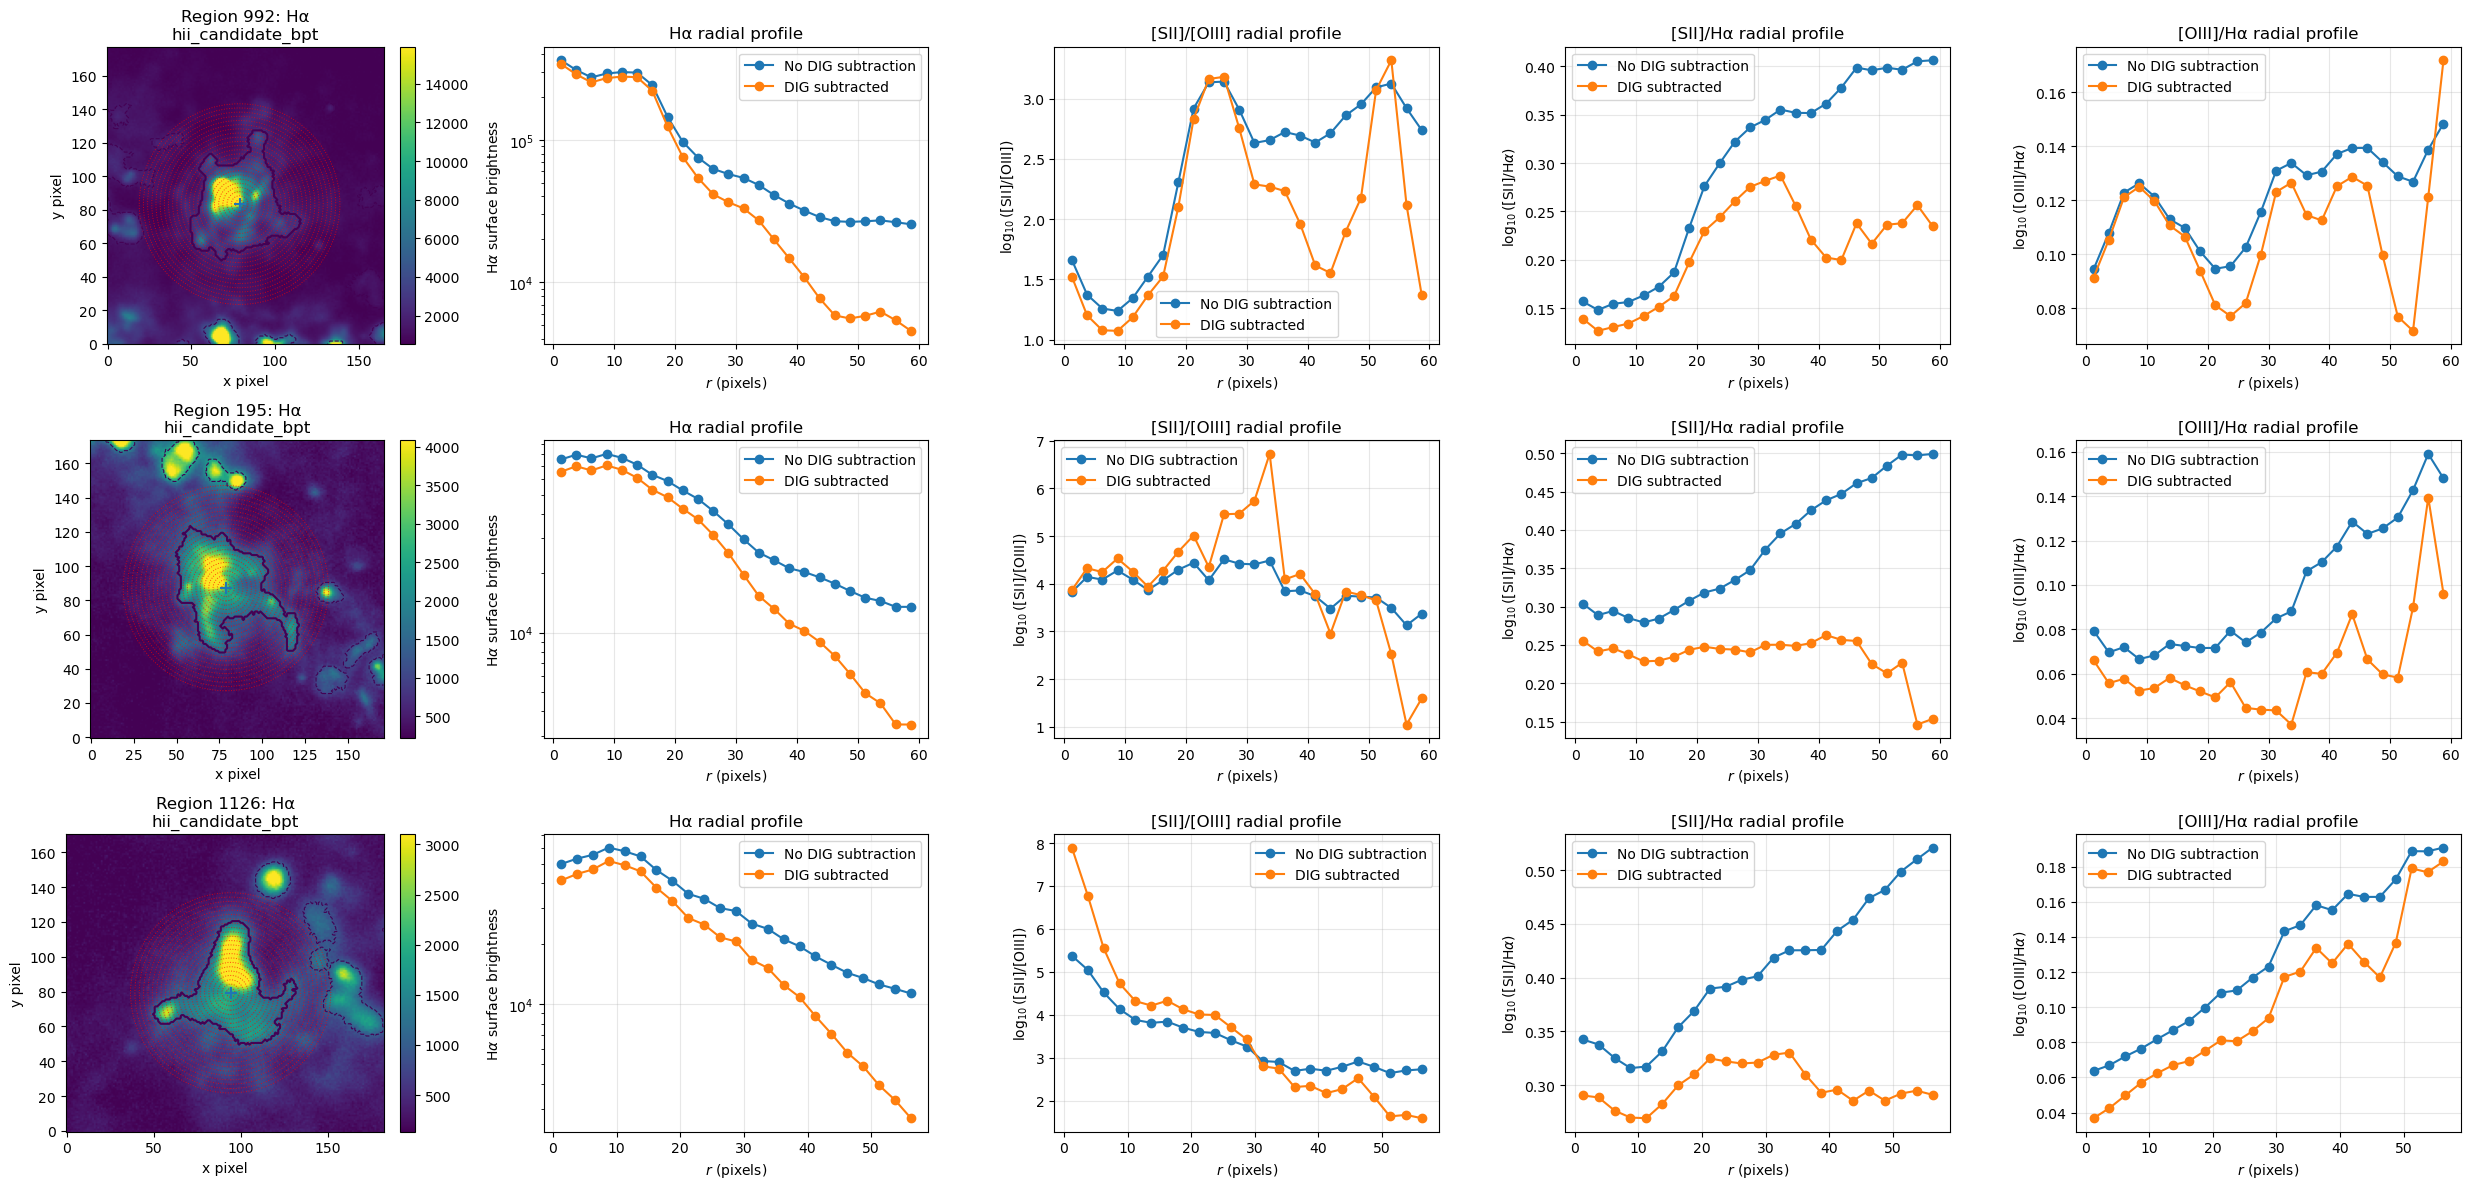

In [13]:
def plot_ratio_profile(ax, profile, column_base, ylabel, title):
    """Plot one raw and DIG-subtracted logarithmic line-ratio profile."""
    ax.plot(
        profile["r_mid_pix"],
        profile[f"{column_base}_raw"],
        marker="o",
        label="No DIG subtraction",
    )
    ax.plot(
        profile["r_mid_pix"],
        profile[f"{column_base}_dig_sub"],
        marker="o",
        label="DIG subtracted",
    )
    ax.set_xlabel(r"$r$ (pixels)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()


def plot_regions(results, output_path=None):
    if not results:
        raise ValueError("No successfully analysed regions are available.")

    n_regions = len(results)
    fig, axes = plt.subplots(
        n_regions,
        5,
        figsize=(25, 4 * n_regions),
        squeeze=False,
    )

    for row_index, result in enumerate(results.values()):
        region_id = result["region_id"]
        profile = result["profile"]
        ha_cutout = result["maps"]["ha"]

        # Column 1: H-alpha cutout.
        ax = axes[row_index, 0]
        finite = ha_cutout[np.isfinite(ha_cutout)]
        vmin, vmax = (
            np.nanpercentile(finite, [5, 99])
            if finite.size else (None, None)
        )

        image = ax.imshow(
            ha_cutout,
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )
        ax.contour(result["region_mask"], levels=[0.5], linewidths=1.5)

        if np.any(result["other_regions"]):
            ax.contour(
                result["other_regions"],
                levels=[0.5],
                linewidths=0.8,
                linestyles="--",
            )

        # Draw the boundaries of the same annuli used for the profiles.
        # edges[0] is zero, so only positive-radius boundaries are drawn.
        for radius in result["radial_edges_pix"][1:]:
            ax.add_patch(
                Circle(
                    (result["xc"], result["yc"]),
                    radius,
                    fill=False,
                    linestyle=":",
                    linewidth=0.7,
                    color="r",
                    alpha=0.7,
                )
            )

        ax.scatter(result["xc"], result["yc"], marker="+", s=80)
        ax.set_title(f"Region {region_id}: Hα\n{result['first_pass_tag']}")
        ax.set_xlabel("x pixel")
        ax.set_ylabel("y pixel")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

        # Column 2: H-alpha surface brightness.
        ax = axes[row_index, 1]
        raw_ok = np.isfinite(profile["ha_sb_raw"]) & (profile["ha_sb_raw"] > 0)
        sub_ok = (
            np.isfinite(profile["ha_sb_dig_sub"])
            & (profile["ha_sb_dig_sub"] > 0)
        )

        ax.plot(
            profile.loc[raw_ok, "r_mid_pix"],
            profile.loc[raw_ok, "ha_sb_raw"],
            marker="o",
            label="No DIG subtraction",
        )
        ax.plot(
            profile.loc[sub_ok, "r_mid_pix"],
            profile.loc[sub_ok, "ha_sb_dig_sub"],
            marker="o",
            label="DIG subtracted",
        )
        ax.set_yscale("log")
        ax.set_xlabel(r"$r$ (pixels)")
        ax.set_ylabel(r"H$\alpha$ surface brightness")
        ax.set_title("Hα radial profile")
        ax.grid(alpha=0.3)
        ax.legend()

        # Columns 3-5: line-ratio profiles.
        plot_ratio_profile(
            axes[row_index, 2],
            profile,
            "log_sii_oiii",
            r"$\log_{10}([\mathrm{SII}]/[\mathrm{OIII}])$",
            "[SII]/[OIII] radial profile",
        )
        plot_ratio_profile(
            axes[row_index, 3],
            profile,
            "log_sii_ha",
            r"$\log_{10}([\mathrm{SII}]/\mathrm{H}\alpha)$",
            "[SII]/Hα radial profile",
        )
        plot_ratio_profile(
            axes[row_index, 4],
            profile,
            "log_oiii_ha",
            r"$\log_{10}([\mathrm{OIII}]/\mathrm{H}\alpha)$",
            "[OIII]/Hα radial profile",
        )

    fig.tight_layout()

    if output_path is not None:
        fig.savefig(output_path, dpi=200, bbox_inches="tight")

    return fig


fig = plot_regions(
    results,
    output_path="multiple_HII_DIG_profile_comparison_pixels.png",
)
plt.show()


In [14]:
if not results:
    raise ValueError("No radial profiles were produced.")

all_profiles = pd.concat(
    [result["profile"] for result in results.values()],
    ignore_index=True,
)

all_profiles.to_csv("multiple_HII_radial_profiles.csv", index=False)
selected_regions.to_csv("selected_HII_regions.csv", index=False)

display(all_profiles.head())
print("Saved:")
print("- multiple_HII_DIG_profile_comparison_pixels.png")
print("- multiple_HII_radial_profiles.csv")
print("- selected_HII_regions.csv")


,region_id,first_pass_tag,bin,r_mid_pix,r_mid_arcsec,r_over_req,inside_region_fraction,ha_sb_raw,ha_sb_dig_sub,log_sii_oiii_raw,log_sii_oiii_dig_sub,log_sii_ha_raw,log_sii_ha_dig_sub,log_oiii_ha_raw,log_oiii_ha_dig_sub
0,992,hii_candidate_bpt,0,1.25,0.25,0.042242,1.0,360410.356060,339434.502331,1.661228,1.522288,0.156885,0.139167,0.094439,0.091420
1,992,hii_candidate_bpt,1,3.75,0.75,0.126725,1.0,307733.355306,286757.501577,1.372664,1.201217,0.148146,0.126535,0.107926,0.105339
2,992,hii_candidate_bpt,2,6.25,1.25,0.211208,1.0,273475.175507,252499.321778,1.257925,1.077305,0.154496,0.130480,0.122818,0.121117
3,992,hii_candidate_bpt,3,8.75,1.75,0.295691,1.0,291229.338361,270253.484632,1.237786,1.072462,0.156337,0.134041,0.126303,0.124985
4,992,hii_candidate_bpt,4,11.25,2.25,0.380174,1.0,297909.634589,276933.780860,1.343991,1.185199,0.163144,0.141901,0.121387,0.119728


Saved:
- multiple_HII_DIG_profile_comparison_pixels.png
- multiple_HII_radial_profiles.csv
- selected_HII_regions.csv
